# EDA — E-commerce brasileiro (Olist)

**Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle)
**Período analisado:** jan/2017 a ago/2018 · ~99 mil pedidos reais e anonimizados de marketplaces brasileiros

### Por que este dataset?
- **Dados reais** de um e-commerce brasileiro (não é dado sintético nem "de brinquedo").
- **9 tabelas relacionadas** (pedidos, itens, pagamentos, avaliações, clientes, vendedores, produtos, geolocalização) → permite análises de vendas, logística, satisfação, geografia e comportamento do cliente.
- Tem **datas, valores, categorias, coordenadas e notas** → rende ótimos filtros e gráficos para um dashboard em Streamlit.

### Perguntas que a EDA responde
1. Como as vendas evoluíram ao longo do tempo? Existe sazonalidade?
2. Quando (dia/hora) as pessoas compram?
3. Onde estão os clientes e como a geografia afeta frete e prazo de entrega?
4. Quais categorias geram mais receita?
5. Como os clientes pagam?
6. A logística cumpre o prazo prometido?
7. **O que derruba a nota de avaliação do cliente?**
8. Os clientes voltam a comprar?

> **Fluxo do notebook:** seção 0 lê os CSVs brutos de `data/raw/`, junta as tabelas e cria as variáveis derivadas → seções 1 a 9 fazem a EDA → seção 12 exporta o dado tratado (e anonimizado) para `data/clean/dataset.csv`, que é o arquivo lido pelo app Streamlit.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 4.5)
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

from pathlib import Path
RAW = Path("../data/raw")      # CSVs brutos do Kaggle (não versionados)
CLEAN = Path("../data/clean")  # dado tratado que o app lê

## 0. Carregamento e preparação dos dados

**Como obter os dados brutos:** baixe o zip em https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce e extraia os 9 CSVs em `data/raw/`.
(Os mesmos arquivos também estão no repositório oficial da Olist: https://github.com/olist/work-at-olist-data, pasta `datasets/`.)

O dataset é relacional (como um banco de dados): cada tabela guarda uma parte da informação e elas se ligam por chaves (`order_id`, `customer_id`, `product_id`, `seller_id`).

In [2]:
def ler(nome):
    return pd.read_csv(RAW / f"olist_{nome}_dataset.csv")

orders, items, pays = ler("orders"), ler("order_items"), ler("order_payments")
reviews, customers, products, sellers = ler("order_reviews"), ler("customers"), ler("products"), ler("sellers")

for nome, df in {"orders": orders, "order_items": items, "order_payments": pays, "order_reviews": reviews,
                 "customers": customers, "products": products, "sellers": sellers}.items():
    print(f"{nome:15s} {df.shape[0]:>7,} linhas × {df.shape[1]:>2} colunas | duplicadas: {df.duplicated().sum()}")

orders           99,441 linhas ×  8 colunas | duplicadas: 0
order_items     112,650 linhas ×  7 colunas | duplicadas: 0
order_payments  103,886 linhas ×  5 colunas | duplicadas: 0
order_reviews    99,224 linhas ×  7 colunas | duplicadas: 0
customers        99,441 linhas ×  5 colunas | duplicadas: 0
products         32,951 linhas ×  9 colunas | duplicadas: 0
sellers           3,095 linhas ×  4 colunas | duplicadas: 0


### 0.1 Tratamentos
- Converter colunas de data para `datetime`.
- **Avaliações:** alguns pedidos têm mais de uma review → fica a mais recente.
- **Pagamentos:** um pedido pode ser pago em mais de uma forma → somamos o valor e guardamos a forma principal (maior valor).
- **Itens:** agregamos por pedido (nº de itens, valor, frete, peso) e guardamos a categoria do item mais caro.
- Traduzimos status/pagamentos para português e criamos a coluna `regiao`.

In [3]:
PAGAMENTOS_PT = {"credit_card": "Cartão de crédito", "boleto": "Boleto", "voucher": "Voucher",
                 "debit_card": "Cartão de débito", "not_defined": "Não definido"}
STATUS_PT = {"delivered": "Entregue", "shipped": "Enviado", "canceled": "Cancelado", "unavailable": "Indisponível",
             "invoiced": "Faturado", "processing": "Em processamento", "created": "Criado", "approved": "Aprovado"}
REGIOES = {"Norte": ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
           "Nordeste": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
           "Centro-Oeste": ["DF", "GO", "MT", "MS"], "Sudeste": ["ES", "MG", "RJ", "SP"], "Sul": ["PR", "RS", "SC"]}
UF_REGIAO = {uf: reg for reg, ufs in REGIOES.items() for uf in ufs}

for col in ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_estimated_delivery_date"]:
    orders[col] = pd.to_datetime(orders[col])

products["categoria"] = (products["product_category_name"].fillna("sem_categoria")
                         .str.replace("_", " ").str.strip().str.capitalize())

# avaliações: 1 por pedido (a mais recente)
reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"])
rev = (reviews.sort_values("review_creation_date").drop_duplicates("order_id", keep="last")
              [["order_id", "review_score"]])

# pagamentos por pedido
pays["tipo_pagamento"] = pays["payment_type"].map(PAGAMENTOS_PT)
pag = pays.groupby("order_id").agg(valor_pago=("payment_value", "sum"), parcelas=("payment_installments", "max"))
pag = pag.join(pays.sort_values("payment_value", ascending=False)
                   .drop_duplicates("order_id").set_index("order_id")[["tipo_pagamento"]]).reset_index()

# itens (com produto e vendedor)
it = (items.merge(products[["product_id", "categoria", "product_weight_g"]], on="product_id", how="left")
           .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left"))
itens_pedido = it.groupby("order_id").agg(n_itens=("order_item_id", "count"), valor_produtos=("price", "sum"),
                                          valor_frete=("freight_value", "sum"), n_vendedores=("seller_id", "nunique"),
                                          peso_total_g=("product_weight_g", "sum"))
itens_pedido = itens_pedido.join(
    it.sort_values("price", ascending=False).drop_duplicates("order_id").set_index("order_id")
      [["categoria", "seller_state"]].rename(columns={"categoria": "categoria_principal",
                                                      "seller_state": "uf_vendedor_principal"})).reset_index()

### 0.2 Tabela de pedidos (1 linha por pedido) e variáveis derivadas
Variáveis criadas a partir das datas:
- `dias_entrega` = entrega real − compra · `dias_prometidos` = data estimada − compra
- `dias_atraso` = entrega real − data estimada (negativo = chegou antes) · `atrasado` = 1 se `dias_atraso > 0`
- `mesmo_estado` = vendedor e cliente no mesmo estado · `cliente_recorrente` = cliente com 2+ pedidos

Também removemos os meses das pontas (set–dez/2016 e set–out/2018), que têm pouquíssimos pedidos e distorceriam as séries temporais.

In [4]:
ped = (orders.merge(customers, on="customer_id", how="left").merge(itens_pedido, on="order_id", how="left")
             .merge(pag, on="order_id", how="left").merge(rev, on="order_id", how="left"))
ped["status"] = ped["order_status"].map(STATUS_PT)
ped["data_compra"] = ped["order_purchase_timestamp"]
ped["ano_mes"] = ped["data_compra"].dt.to_period("M").astype(str)
ped["dia_semana"] = ped["data_compra"].dt.dayofweek   # 0 = segunda
ped["hora"] = ped["data_compra"].dt.hour
ped["regiao"] = ped["customer_state"].map(UF_REGIAO)

dia = 86400
ped["dias_entrega"] = ((ped["order_delivered_customer_date"] - ped["data_compra"]).dt.total_seconds() / dia).round(2)
ped["dias_prometidos"] = ((ped["order_estimated_delivery_date"] - ped["data_compra"]).dt.total_seconds() / dia).round(2)
ped["dias_atraso"] = ((ped["order_delivered_customer_date"] - ped["order_estimated_delivery_date"]).dt.total_seconds() / dia).round(2)
ped["atrasado"] = np.where(ped["dias_entrega"].notna(), (ped["dias_atraso"] > 0).astype(float), np.nan)
ped["mesmo_estado"] = ped["customer_state"] == ped["uf_vendedor_principal"]
ped["cliente_recorrente"] = ped.groupby("customer_unique_id")["order_id"].transform("count") > 1

ped = ped[(ped["data_compra"] >= "2017-01-01") & (ped["data_compra"] < "2018-09-01")]
pedidos = ped[["order_id", "customer_unique_id", "status", "data_compra", "ano_mes", "dia_semana", "hora",
               "customer_state", "regiao", "n_itens", "valor_produtos", "valor_frete", "valor_pago", "parcelas",
               "tipo_pagamento", "n_vendedores", "peso_total_g", "categoria_principal", "uf_vendedor_principal",
               "mesmo_estado", "dias_entrega", "dias_prometidos", "dias_atraso", "atrasado", "review_score",
               "cliente_recorrente"]].rename(columns={"customer_state": "uf"}).reset_index(drop=True)

# tabela de itens (1 linha por item) para as análises de categoria
itens = (it.merge(pedidos[["order_id", "data_compra", "uf", "review_score"]], on="order_id", how="inner")
           .rename(columns={"price": "preco", "freight_value": "frete", "seller_state": "uf_vendedor"}))
print("pedidos:", pedidos.shape, "| itens:", itens.shape)
pedidos.head()

pedidos: (99092, 26) | itens: (112279, 13)


,order_id,customer_unique_id,status,data_compra,ano_mes,dia_semana,hora,uf,regiao,n_itens,valor_produtos,valor_frete,valor_pago,parcelas,tipo_pagamento,n_vendedores,peso_total_g,categoria_principal,uf_vendedor_principal,mesmo_estado,dias_entrega,dias_prometidos,dias_atraso,atrasado,review_score,cliente_recorrente
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,Entregue,2017-10-02 10:56:33,2017-10,0,10,SP,Sudeste,1.00,29.99,8.72,38.71,1.00,Voucher,1.00,500.00,Utilidades domesticas,SP,True,8.44,15.54,-7.11,0.00,4.00,True
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,Entregue,2018-07-24 20:41:37,2018-07,1,20,BA,Nordeste,1.00,118.70,22.76,141.46,1.00,Boleto,1.00,400.00,Perfumaria,SP,False,13.78,19.14,-5.36,0.00,4.00,False
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,Entregue,2018-08-08 08:38:49,2018-08,2,8,GO,Centro-Oeste,1.00,159.90,19.22,179.12,3.00,Cartão de crédito,1.00,420.00,Automotivo,SP,False,9.39,26.64,-17.25,0.00,5.00,False
3,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,Entregue,2017-11-18 19:28:06,2017-11,5,19,RN,Nordeste,1.00,45.00,27.20,72.20,1.00,Cartão de crédito,1.00,450.00,Pet shop,MG,False,13.21,26.19,-12.98,0.00,5.00,False
4,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,Entregue,2018-02-13 21:18:39,2018-02,1,21,SP,Sudeste,1.00,19.90,8.72,28.62,1.00,Cartão de crédito,1.00,250.00,Papelaria,SP,True,2.87,12.11,-9.24,0.00,5.00,False


## 1. Visão geral e qualidade dos dados

In [5]:
pedidos.info()

<class 'pandas.DataFrame'>
RangeIndex: 99092 entries, 0 to 99091
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   order_id               99092 non-null  str           
 1   customer_unique_id     99092 non-null  str           
 2   status                 99092 non-null  str           
 3   data_compra            99092 non-null  datetime64[us]
 4   ano_mes                99092 non-null  str           
 5   dia_semana             99092 non-null  int32         
 6   hora                   99092 non-null  int32         
 7   uf                     99092 non-null  str           
 8   regiao                 99092 non-null  str           
 9   n_itens                98353 non-null  float64       
 10  valor_produtos         98353 non-null  float64       
 11  valor_frete            98353 non-null  float64       
 12  valor_pago             99092 non-null  float64       
 13  parcelas    

In [6]:
nulos = pedidos.isna().mean().mul(100).round(2)
nulos[nulos > 0].sort_values(ascending=False).to_frame("% nulos")

,% nulos
dias_entrega,2.91
atrasado,2.91
dias_atraso,2.91
review_score,0.77
valor_frete,0.75
n_itens,0.75
valor_produtos,0.75
uf_vendedor_principal,0.75
categoria_principal,0.75
peso_total_g,0.75


**Sobre os nulos:**
- `dias_entrega`, `dias_atraso`, `atrasado` (~2,9%) → pedidos que **ainda não foram entregues** (cancelados, enviados, indisponíveis). É esperado, não é erro.
- `review_score` (~0,8%) → pedidos sem avaliação.
- `n_itens`, `valor_produtos`, `categoria_principal` (~0,7%) → pedidos sem itens registrados (quase todos cancelados/indisponíveis).

Nas análises de entrega, usamos só pedidos **entregues**.

In [7]:
status = pedidos["status"].value_counts()
print((status / len(pedidos) * 100).round(2).astype(str) + " %")

status
Entregue            97.09 %
Enviado              1.11 %
Indisponível         0.61 %
Cancelado            0.59 %
Em processamento      0.3 %
Faturado              0.3 %
Criado               0.01 %
Aprovado              0.0 %
Name: count, dtype: str


In [8]:
entregues = pedidos[pedidos["status"] == "Entregue"].copy()
kpis = {
    "Pedidos": len(pedidos),
    "Clientes únicos": pedidos["customer_unique_id"].nunique(),
    "Receita total (R$)": pedidos["valor_pago"].sum(),
    "Ticket médio (R$)": pedidos["valor_pago"].mean(),
    "Ticket mediano (R$)": pedidos["valor_pago"].median(),
    "Nota média": pedidos["review_score"].mean(),
    "Prazo médio de entrega (dias)": entregues["dias_entrega"].mean(),
    "% entregas atrasadas": entregues["atrasado"].mean() * 100,
}
pd.Series(kpis).round(2).to_frame("valor")

,valor
Pedidos,"99,092.00"
Clientes únicos,"95,774.00"
Receita total (R$),"15,944,480.57"
Ticket médio (R$),160.91
Ticket mediano (R$),105.28
Nota média,4.09
Prazo médio de entrega (dias),12.54
% entregas atrasadas,8.12


In [9]:
pedidos[["valor_pago", "valor_produtos", "valor_frete", "n_itens", "parcelas", "dias_entrega", "review_score"]].describe().T

,count,mean,std,min,25%,50%,75%,max
valor_pago,"99,092.00",160.91,221.93,0.00,62.00,105.28,176.87,"13,664.08"
valor_produtos,"98,353.00",137.68,210.68,0.85,45.90,86.90,149.90,"13,440.00"
valor_frete,"98,353.00",22.87,21.83,0.00,13.85,17.18,24.06,"1,794.96"
n_itens,"98,353.00",1.14,0.54,1.00,1.00,1.00,1.00,21.00
parcelas,"99,092.00",2.93,2.71,0.00,1.00,2.00,4.00,24.00
dias_entrega,"96,204.00",12.54,9.53,0.53,6.76,10.21,15.68,209.63
review_score,"98,330.00",4.09,1.35,1.00,4.00,5.00,5.00,5.00


O ticket **médio** (~R\$ 160) é bem maior que o **mediano** (~R\$ 105): a distribuição de valores é **assimétrica à direita** (poucos pedidos muito caros puxam a média). Por isso usamos escala log nos histogramas de valor.

## 2. Evolução das vendas no tempo

         pedidos      receita
ano_mes                      
2017-10     4631   779,677.88
2017-11     7544 1,194,882.80
2017-12     5673   878,401.48


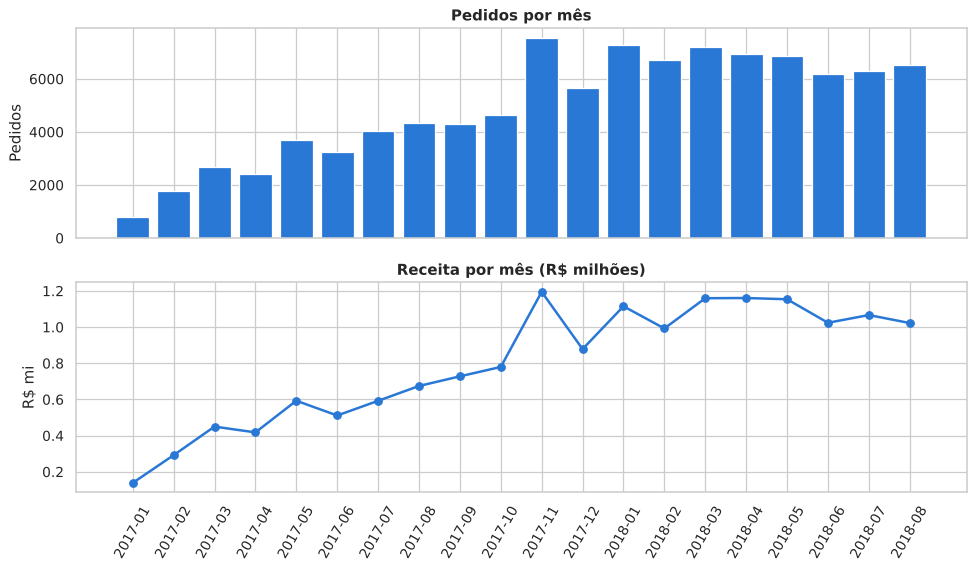

In [10]:
mensal = pedidos.groupby("ano_mes").agg(pedidos=("order_id", "count"), receita=("valor_pago", "sum"))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
ax1.bar(mensal.index, mensal["pedidos"], color="#2a78d6")
ax1.set_title("Pedidos por mês"); ax1.set_ylabel("Pedidos")
ax2.plot(mensal.index, mensal["receita"] / 1e6, color="#2a78d6", marker="o", lw=2)
ax2.set_title("Receita por mês (R$ milhões)"); ax2.set_ylabel("R$ mi")
ax2.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()
print(mensal.loc["2017-10":"2017-12"])

Dias com mais pedidos:
data_compra
2017-11-24    1176
2017-11-25     499
2017-11-27     403
2017-11-26     391
2017-11-28     380
Name: order_id, dtype: int64


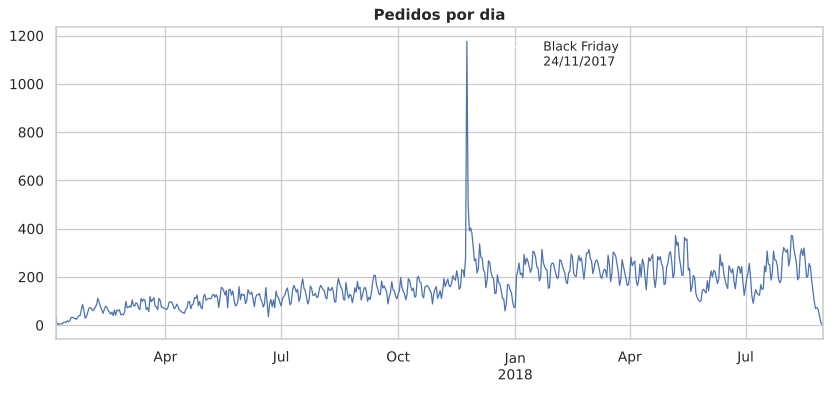

In [11]:
diario = pedidos.set_index("data_compra").resample("D")["order_id"].count()
top = diario.sort_values(ascending=False).head(5)
ax = diario.plot(lw=1, color="#4C72B0", title="Pedidos por dia")
ax.annotate("Black Friday\n24/11/2017", xy=(top.index[0], top.iloc[0]), xytext=(top.index[0] + pd.Timedelta(days=60), top.iloc[0] - 100),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_xlabel(""); plt.show()
print("Dias com mais pedidos:"); print(top)

In [12]:
r17 = pedidos.query("data_compra < '2017-09-01' and data_compra >= '2017-01-01'")["valor_pago"].sum()
r18 = pedidos.query("data_compra >= '2018-01-01'")["valor_pago"].sum()
print(f"Receita jan-ago/2017: R$ {r17:,.0f}")
print(f"Receita jan-ago/2018: R$ {r18:,.0f}")
print(f"Crescimento: {(r18 / r17 - 1) * 100:.1f}%")

Receita jan-ago/2017: R$ 3,669,022
Receita jan-ago/2018: R$ 8,694,734
Crescimento: 137.0%


**Insights:**
- Crescimento forte ao longo de 2017 e **estabilização em 2018** (~6–7 mil pedidos/mês).
- Receita de jan–ago/2018 é **mais que o dobro** do mesmo período de 2017.
- **Black Friday (24/11/2017)** é, de longe, o dia com mais pedidos do dataset — novembro/2017 é o pico mensal.

## 3. Quando as pessoas compram?

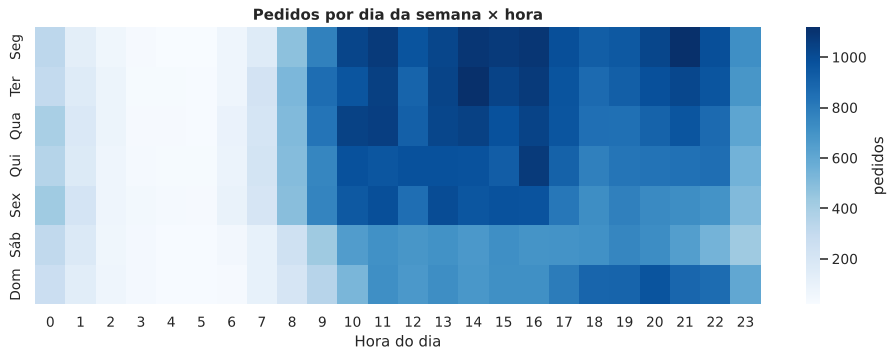

In [13]:
dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
heat = pedidos.pivot_table(index="dia_semana", columns="hora", values="order_id", aggfunc="count")
heat.index = dias
plt.figure(figsize=(13, 4))
sns.heatmap(heat, cmap="Blues", cbar_kws={"label": "pedidos"})
plt.title("Pedidos por dia da semana × hora"); plt.xlabel("Hora do dia"); plt.ylabel("")
plt.show()

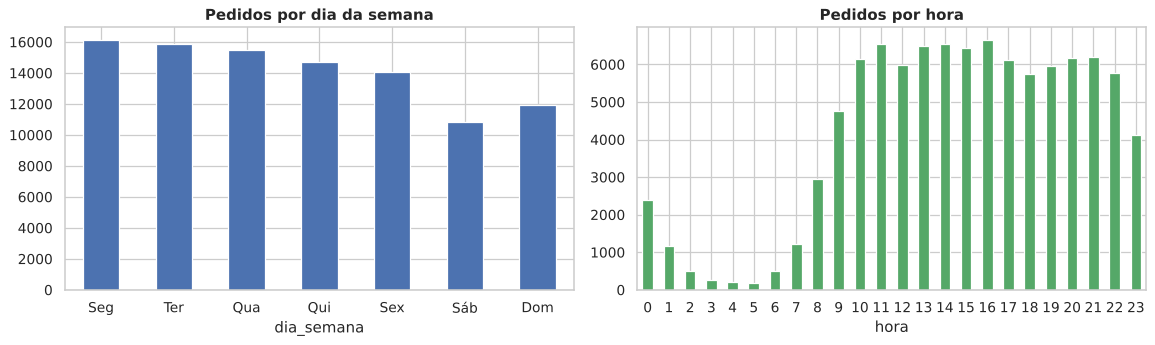

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pedidos["dia_semana"].map(dict(enumerate(dias))).value_counts().reindex(dias).plot.bar(ax=axes[0], color="#4C72B0", rot=0, title="Pedidos por dia da semana")
pedidos["hora"].value_counts().sort_index().plot.bar(ax=axes[1], color="#55A868", rot=0, title="Pedidos por hora")
plt.tight_layout(); plt.show()

**Insights:** as compras se concentram em **dias úteis (seg–ter lideram)** e no horário comercial, **das 10h às 22h**, com leve pico no início da tarde e à noite. O **sábado** é o dia mais fraco; já o **domingo à noite** volta a ter bastante movimento. Madrugada (1h–6h) quase não tem pedidos → bom horário para manutenção/deploy.

## 4. Geografia

In [15]:
por_uf = pedidos.groupby("uf").agg(
    pedidos=("order_id", "count"),
    receita=("valor_pago", "sum"),
    ticket_medio=("valor_pago", "mean"),
    frete_medio=("valor_frete", "mean"),
    dias_entrega=("dias_entrega", "mean"),
    nota=("review_score", "mean"),
).sort_values("pedidos", ascending=False)
por_uf["% pedidos"] = por_uf["pedidos"] / por_uf["pedidos"].sum() * 100
por_uf.head(10)

,pedidos,receita,ticket_medio,frete_medio,dias_entrega,nota,% pedidos
uf,,,,,,,
SP,41621,"5,977,851.25",143.63,17.42,8.74,4.18,42.00
RJ,12792,"2,130,651.30",166.56,23.97,15.30,3.88,12.91
MG,11591,"1,866,032.13",160.99,23.51,11.99,4.14,11.70
RS,5441,"886,107.84",162.86,25.00,15.29,4.14,5.49
PR,5025,"808,556.41",160.91,23.61,11.97,4.18,5.07
SC,3625,"619,941.97",171.02,24.82,14.95,4.08,3.66
BA,3376,"615,650.48",182.36,29.83,19.33,3.86,3.41
DF,2134,"353,940.97",165.86,23.96,12.94,4.07,2.15
ES,2029,"324,900.41",160.13,24.57,15.78,4.04,2.05


              valor_frete  dias_entrega  review_score
regiao                                               
Sudeste             19.91         10.73          4.11
Sul                 24.46         14.02          4.14
Centro-Oeste        26.69         15.01          4.07
Nordeste            35.98         19.99          3.89
Norte               41.35         22.59          3.96


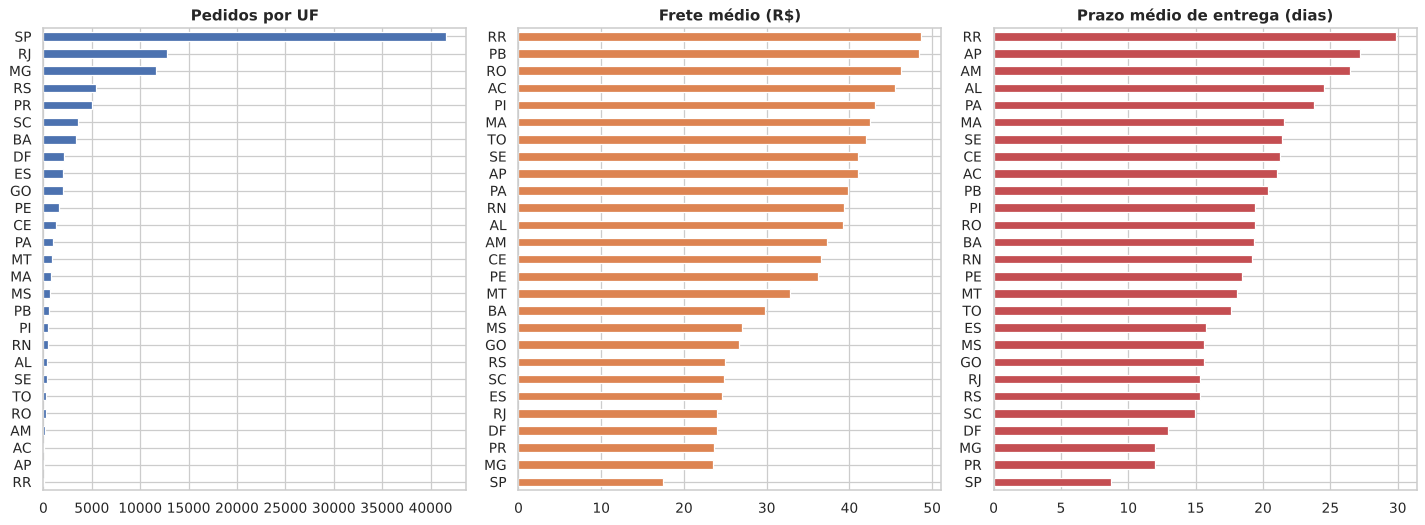

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
por_uf["pedidos"].sort_values().plot.barh(ax=axes[0], color="#4C72B0", title="Pedidos por UF")
por_uf["frete_medio"].sort_values().plot.barh(ax=axes[1], color="#DD8452", title="Frete médio (R$)")
por_uf["dias_entrega"].sort_values().plot.barh(ax=axes[2], color="#C44E52", title="Prazo médio de entrega (dias)")
for a in axes: a.set_ylabel("")
plt.tight_layout(); plt.show()
print(pedidos.groupby("regiao")[["valor_frete", "dias_entrega", "review_score"]].mean().sort_values("dias_entrega"))

In [17]:
vend = itens["uf_vendedor"].value_counts(normalize=True).mul(100).head(5).round(1)
print("% dos itens vendidos por UF do VENDEDOR:"); print(vend)
print()
print("% pedidos com vendedor no mesmo estado do cliente:", round(pedidos["mesmo_estado"].mean() * 100, 1))
print(pedidos.groupby("mesmo_estado")[["valor_frete", "dias_entrega", "atrasado", "review_score"]].mean())

% dos itens vendidos por UF do VENDEDOR:
uf_vendedor
SP   71.40
MG    7.80
PR    7.70
RJ    4.30
SC    3.60
Name: proportion, dtype: float64

% pedidos com vendedor no mesmo estado do cliente: 35.7
              valor_frete  dias_entrega  atrasado  review_score
mesmo_estado                                                   
False               27.01         15.13      0.09          4.02
True                15.49          7.92      0.06          4.21


**Insights:**
- **SP sozinho concentra ~42% dos pedidos**; Sudeste domina. Mas o mais importante: **~70% dos itens são vendidos por vendedores de SP**.
- Consequência: quanto mais longe de SP, **maior o frete e o prazo**. Norte e Nordeste pagam frete bem mais caro e esperam quase o dobro do tempo (RR, AP e AM passam de 25 dias) — e dão **notas menores**.
- Quando cliente e vendedor estão no **mesmo estado**, a entrega é muito mais rápida e barata.

## 5. Produtos e categorias

Total de categorias: 74


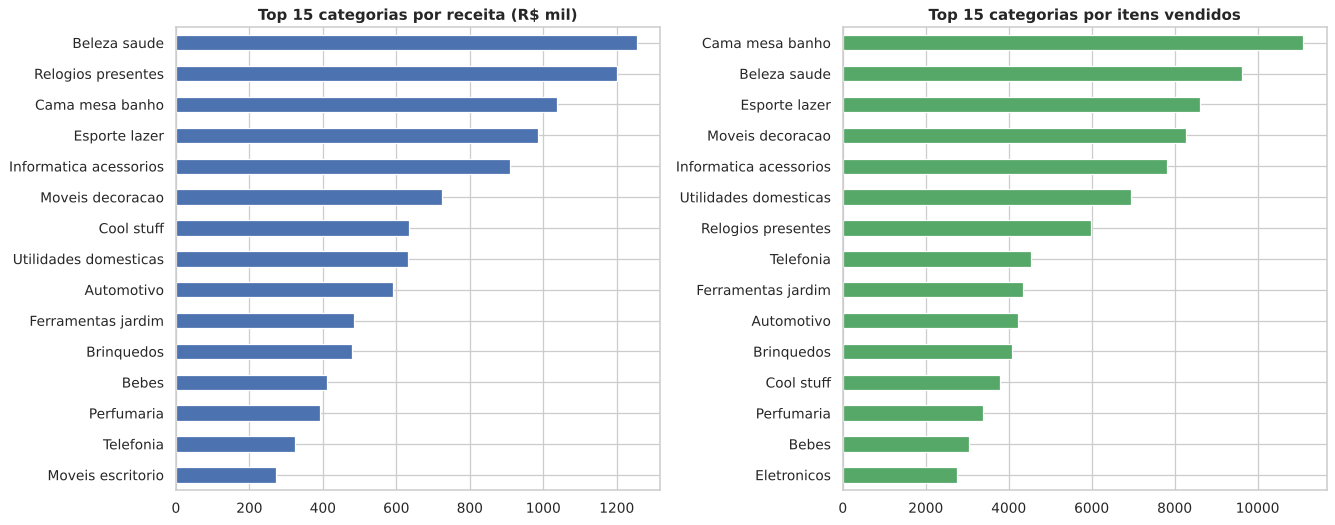

In [18]:
cat = itens.groupby("categoria").agg(
    itens=("product_id", "count"),
    receita=("preco", "sum"),
    preco_medio=("preco", "mean"),
    nota=("review_score", "mean"),
).sort_values("receita", ascending=False)
print("Total de categorias:", cat.shape[0])
top_cat = cat.head(15)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_cat["receita"].div(1e3).sort_values().plot.barh(ax=axes[0], color="#4C72B0", title="Top 15 categorias por receita (R$ mil)")
cat.sort_values("itens").tail(15)["itens"].plot.barh(ax=axes[1], color="#55A868", title="Top 15 categorias por itens vendidos")
for a in axes: a.set_ylabel("")
plt.tight_layout(); plt.show()

As 10 maiores categorias = 62.4% da receita


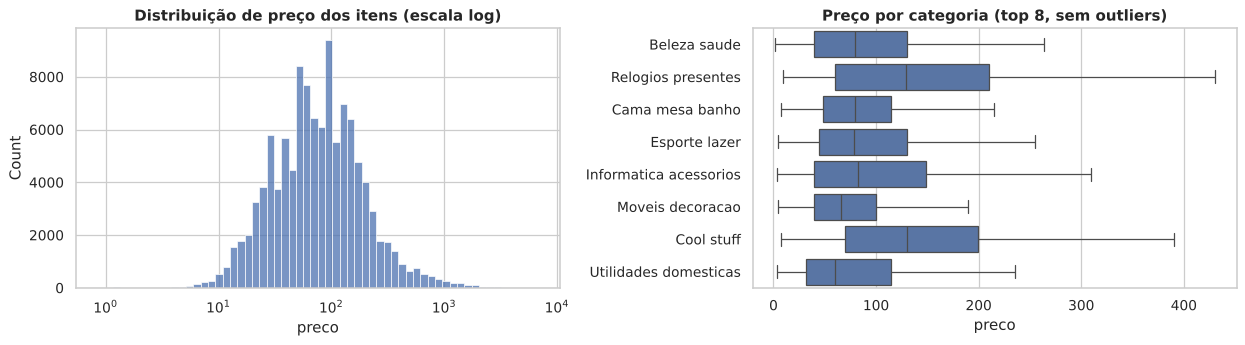

In [19]:
top10_share = cat["receita"].head(10).sum() / cat["receita"].sum() * 100
print(f"As 10 maiores categorias = {top10_share:.1f}% da receita")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(itens["preco"], bins=60, log_scale=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribuição de preço dos itens (escala log)")
sns.boxplot(data=itens[itens["categoria"].isin(cat.head(8).index)], y="categoria", x="preco",
            showfliers=False, ax=axes[1], order=cat.head(8).index)
axes[1].set_title("Preço por categoria (top 8, sem outliers)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Insights:**
- **Beleza/saúde, relógios/presentes e cama/mesa/banho** lideram a receita. Cama/mesa/banho é a campeã em **volume** de itens, mas tem preço médio baixo.
- Relógios/presentes tem poucos itens, mas preço médio alto → muita receita.
- A distribuição de preço é **log-normal**: a maioria dos itens custa entre R\$ 40 e R\$ 140.

## 6. Pagamentos

% pedidos de cartão parcelados (2x+): 67.9


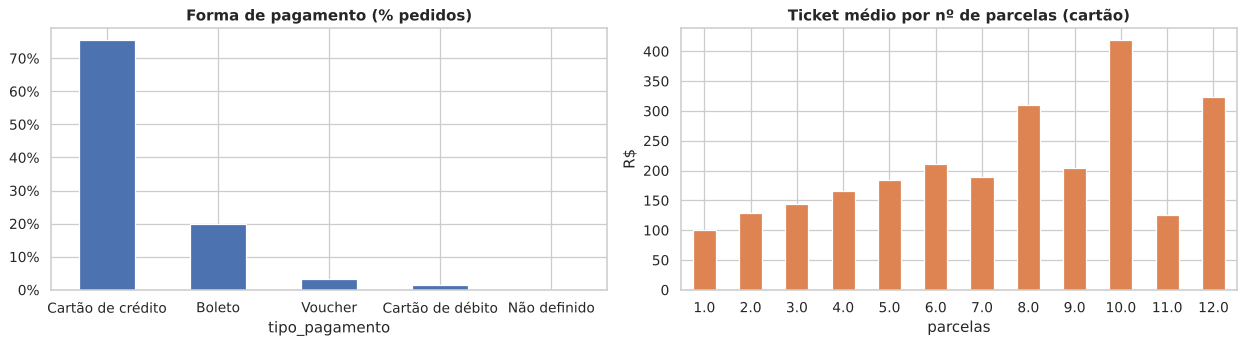

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pedidos["tipo_pagamento"].value_counts(normalize=True).mul(100).plot.bar(ax=axes[0], rot=0, color="#4C72B0", title="Forma de pagamento (% pedidos)")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
cc = pedidos[pedidos["tipo_pagamento"] == "Cartão de crédito"]
cc.groupby("parcelas")["valor_pago"].mean().loc[1:12].plot.bar(ax=axes[1], rot=0, color="#DD8452", title="Ticket médio por nº de parcelas (cartão)")
axes[1].set_ylabel("R$")
plt.tight_layout(); plt.show()
print("% pedidos de cartão parcelados (2x+):", round((cc["parcelas"] > 1).mean() * 100, 1))

**Insights:** **cartão de crédito ≈ 75%** dos pedidos e **boleto ≈ 20%** (bem brasileiro 🇧🇷). Cerca de **68%** das compras no cartão são parceladas, e **quanto maior o valor, mais parcelas** — o parcelamento é ferramenta para viabilizar compras caras.

## 7. Logística: o prazo é cumprido?

Entregues ANTES do prazo: 91.9%
Atraso médio de quem atrasou: 9.6 dias
Prazo prometido médio: 23.6 dias | real: 12.5 dias


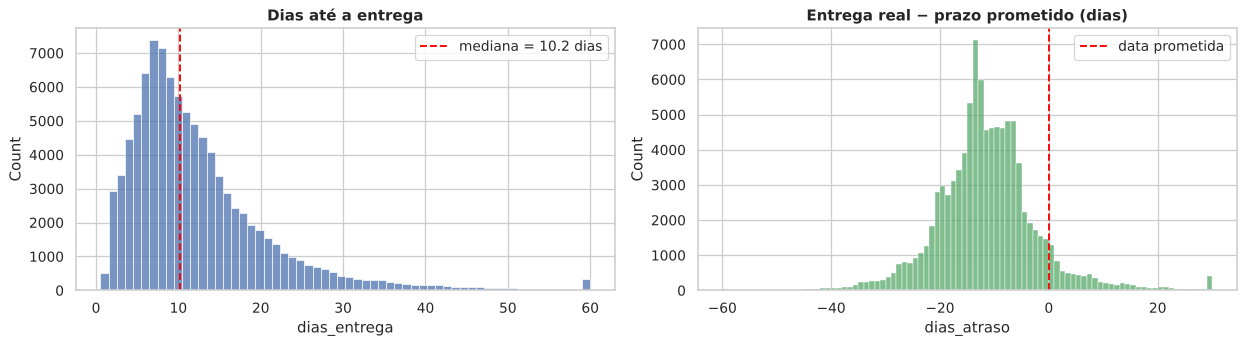

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(entregues["dias_entrega"].clip(upper=60), bins=60, ax=axes[0], color="#4C72B0")
axes[0].axvline(entregues["dias_entrega"].median(), color="red", ls="--", label=f"mediana = {entregues['dias_entrega'].median():.1f} dias")
axes[0].set_title("Dias até a entrega"); axes[0].legend()
sns.histplot(entregues["dias_atraso"].clip(-60, 30), bins=90, ax=axes[1], color="#55A868")
axes[1].axvline(0, color="red", ls="--", label="data prometida")
axes[1].set_title("Entrega real − prazo prometido (dias)"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Entregues ANTES do prazo: {(entregues['dias_atraso'] < 0).mean() * 100:.1f}%")
print(f"Atraso médio de quem atrasou: {entregues.loc[entregues['dias_atraso'] > 0, 'dias_atraso'].mean():.1f} dias")
print(f"Prazo prometido médio: {entregues['dias_prometidos'].mean():.1f} dias | real: {entregues['dias_entrega'].mean():.1f} dias")

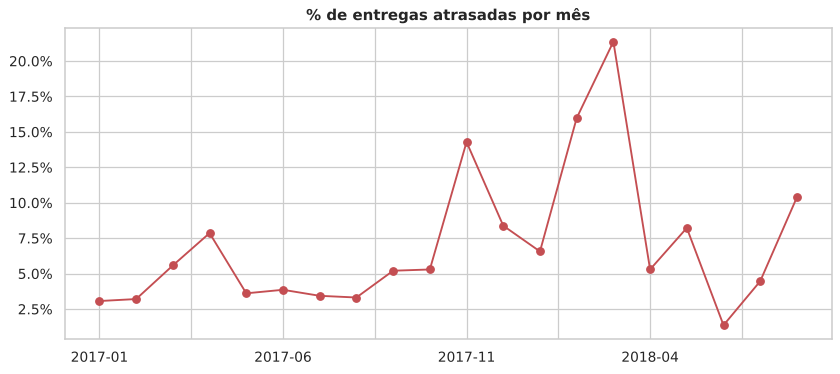

In [22]:
atraso_mes = entregues.groupby("ano_mes")["atrasado"].mean().mul(100)
ax = atraso_mes.plot(marker="o", color="#C44E52", title="% de entregas atrasadas por mês")
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlabel("")
plt.show()

**Insights:**
- A mediana é de ~10 dias, mas há uma cauda longa (pedidos levando mais de 30 dias).
- **A Olist promete prazos folgados**: em média promete ~24 dias e entrega em ~12. Por isso ~92% chegam antes do prazo.
- Ainda assim, **~8% atrasam**, e os atrasos disparam em momentos de pico: **nov/2017 (Black Friday, ~14%)** e **fev–mar/2018 (chegando a ~21%)**.

## 8. Satisfação do cliente — o que derruba a nota?

          mean  count
atrasado             
0.00      4.29  87908
1.00      2.56   7652
% notas 1 entre atrasados: 45.3
% notas 1 entre no prazo : 6.5


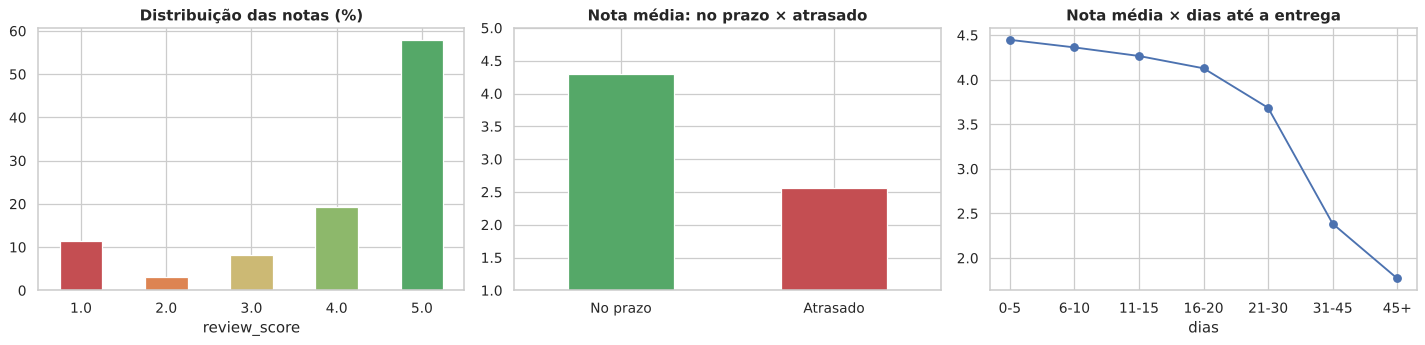

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
pedidos["review_score"].value_counts(normalize=True).sort_index().mul(100).plot.bar(ax=axes[0], rot=0, color=["#C44E52", "#DD8452", "#CCB974", "#8DB86B", "#55A868"], title="Distribuição das notas (%)")
entregues.groupby("atrasado")["review_score"].mean().rename({0: "No prazo", 1: "Atrasado"}).plot.bar(ax=axes[1], rot=0, color=["#55A868", "#C44E52"], title="Nota média: no prazo × atrasado")
axes[1].set_ylim(1, 5); axes[1].set_xlabel("")
faixas = pd.cut(entregues["dias_entrega"], [0, 5, 10, 15, 20, 30, 45, 300], labels=["0-5", "6-10", "11-15", "16-20", "21-30", "31-45", "45+"])
entregues.groupby(faixas, observed=True)["review_score"].mean().plot(ax=axes[2], marker="o", color="#4C72B0", title="Nota média × dias até a entrega")
axes[2].set_xlabel("dias")
plt.tight_layout(); plt.show()
print(entregues.groupby("atrasado")["review_score"].agg(["mean", "count"]))
print("% notas 1 entre atrasados:", round((entregues.loc[entregues.atrasado == 1, "review_score"] == 1).mean() * 100, 1))
print("% notas 1 entre no prazo :", round((entregues.loc[entregues.atrasado == 0, "review_score"] == 1).mean() * 100, 1))

In [24]:
print("Nota média por status do pedido:")
print(pedidos.groupby("status")["review_score"].agg(["mean", "count"]).sort_values("count", ascending=False).head(6))
print()
print("Nota média por nº de vendedores no pedido:")
print(pedidos.groupby("n_vendedores")["review_score"].agg(["mean", "count"]).head(4))

Nota média por status do pedido:
                  mean  count
status                       
Entregue          4.16  95568
Enviado           2.00   1024
Indisponível      1.53    588
Cancelado         1.81    561
Em processamento  1.27    293
Faturado          1.62    291

Nota média por nº de vendedores no pedido:
              mean  count
n_vendedores             
1.00          4.12  96349
2.00          2.89   1201
3.00          2.35     54
4.00          1.00      3


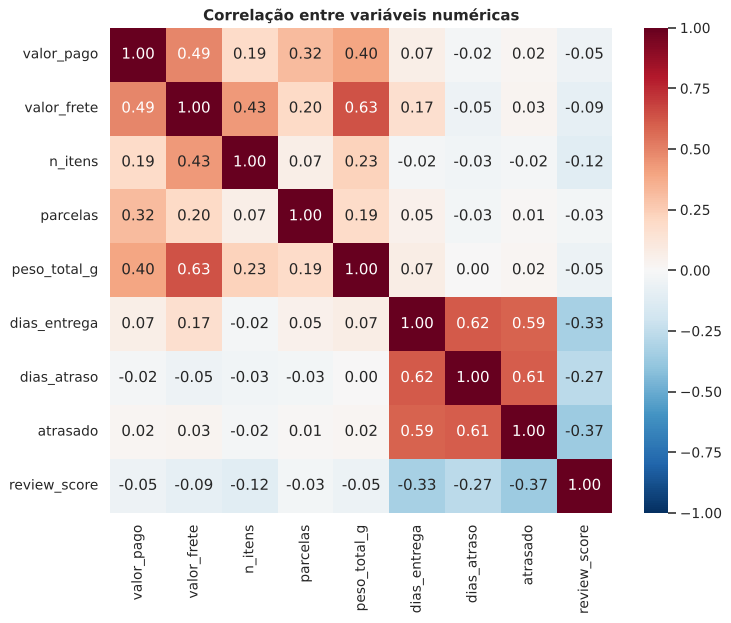

In [25]:
num = pedidos[["valor_pago", "valor_frete", "n_itens", "parcelas", "peso_total_g", "dias_entrega", "dias_atraso", "atrasado", "review_score"]]
plt.figure(figsize=(9, 7))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlação entre variáveis numéricas"); plt.show()

In [26]:
nota_cat = cat[cat["itens"] >= 500]["nota"].sort_values()
print("Piores categorias (mín. 500 itens):"); print(nota_cat.head(5).round(2))
print("\nMelhores categorias:"); print(nota_cat.tail(5).round(2))

Piores categorias (mín. 500 itens):
categoria
Moveis escritorio   3.49
Sem categoria       3.83
Cama mesa banho     3.90
Moveis sala         3.90
Moveis decoracao    3.91
Name: nota, dtype: float64

Melhores categorias:
categoria
Pet shop                 4.18
Papelaria                4.20
Alimentos                4.22
Malas acessorios         4.32
Livros interesse geral   4.45
Name: nota, dtype: float64


**Insights (o principal achado da EDA):**
- ~58% das notas são 5, mas **~11% são nota 1** — distribuição polarizada.
- **Atraso é o fator nº 1 de insatisfação**: a nota média cai de ~4,3 (no prazo) para ~2,6 (atrasado). Quase metade dos pedidos atrasados recebe **nota 1**.
- A nota cai de forma contínua conforme o prazo de entrega aumenta.
- Pedidos com **mais de um vendedor** (que chegam em pacotes separados) têm nota menor.
- Na matriz de correlação, `review_score` se relaciona com **dias_atraso / atrasado / dias_entrega** — valor do pedido e frete quase não importam.
- 👉 **Recomendação de negócio:** investir em logística (principalmente para N/NE e em períodos de pico) tem mais impacto na satisfação do que preço.

## 9. Os clientes voltam?

In [27]:
compras_cli = pedidos.groupby("customer_unique_id")["order_id"].count()
print(f"Clientes únicos: {len(compras_cli):,}")
print(f"Clientes com 2+ pedidos: {(compras_cli > 1).mean() * 100:.2f}%")
print(compras_cli.value_counts().head(5))

Clientes únicos: 95,774
Clientes com 2+ pedidos: 3.11%
order_id
1    92799
2     2728
3      198
4       30
5        8
Name: count, dtype: int64


**Insight:** só **~3% dos clientes compram mais de uma vez**. O negócio depende quase totalmente de **aquisição** de novos clientes — retenção é uma enorme oportunidade (cupom pós-compra, programa de fidelidade, e principalmente: **não atrasar a primeira entrega**).

## 10. Conclusões

| # | Achado | Implicação |
|---|---|---|
| 1 | Vendas mais que dobraram de 2017 para 2018; pico na Black Friday | Planejar estoque/logística para nov–dez |
| 2 | Compras em dias úteis, 10h–22h | Campanhas e push nesse horário |
| 3 | ~42% dos pedidos e ~70% dos vendedores em SP | Frete e prazo maiores no N/NE → atrair vendedores fora de SP |
| 4 | Beleza/saúde, relógios e cama/mesa/banho lideram receita | Foco comercial nessas categorias |
| 5 | Cartão de crédito ~75%, parcelamento cresce com o valor | Manter opções de parcelamento |
| 6 | ~8% de atrasos, concentrados em picos | Reforçar operação em datas sazonais |
| 7 | **Atraso derruba a nota de ~4,3 para ~2,6** | Logística é o principal motor de satisfação |
| 8 | Só ~3% de recompra | Grande oportunidade de retenção |

## 11. Do EDA para o Streamlit
O app (`app.py`) tem **duas abas**:
1. **Dashboard 1 — Laboratório de distribuição e correlação:** escolha as variáveis quantitativas (valor, frete, prazos, nota...) e veja o **heatmap de correlação** e **um histograma por variável**. É a seção 8 desta EDA, só que interativa.
2. **Dashboard 2 — Painel da Gerência de Logística:** KPIs de prazo, atraso e frete, e os gráficos que mostram onde e quando a entrega falha e como isso afeta a nota.

Na barra lateral: **seletor de variáveis** e **slider de nota de avaliação** (permite excluir notas da análise, ex.: ver só pedidos com nota 1–2).

## 12. Exportação do dado tratado para o Streamlit

O app só lê `data/clean/dataset.csv`. Antes de exportar, **removemos dados sensíveis/identificadores**:
- `order_id` e `customer_unique_id` (identificadores, ainda que anonimizados pela Olist);
- CEP e cidade do cliente (localização fina) — fica só **UF e região**;
- textos livres das avaliações (podem conter nomes, telefones etc.) — não são exportados.

In [28]:
dataset = pedidos.drop(columns=["order_id", "customer_unique_id"]).copy()
dataset["data_compra"] = dataset["data_compra"].dt.date
CLEAN.mkdir(parents=True, exist_ok=True)
dataset.to_csv(CLEAN / "dataset.csv", index=False)
print(dataset.shape, f"{(CLEAN / 'dataset.csv').stat().st_size / 1e6:.1f} MB")
print(list(dataset.columns))

(99092, 24) 15.1 MB
['status', 'data_compra', 'ano_mes', 'dia_semana', 'hora', 'uf', 'regiao', 'n_itens', 'valor_produtos', 'valor_frete', 'valor_pago', 'parcelas', 'tipo_pagamento', 'n_vendedores', 'peso_total_g', 'categoria_principal', 'uf_vendedor_principal', 'mesmo_estado', 'dias_entrega', 'dias_prometidos', 'dias_atraso', 'atrasado', 'review_score', 'cliente_recorrente']
